<a href="https://colab.research.google.com/github/Danyademik/EMPI-PR-1.2/blob/main/%D0%9F%D0%A0_1_2_%D0%9A%D0%BB%D0%B0%D1%81%D0%B8%D1%84%D1%96%D0%BA%D0%B0%D1%86%D1%96%D1%8F.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
# СЛУЖБОВИЙ БЛОК: Завантаження даних та допоміжна функція візуалізації
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import linear_model
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import (
    confusion_matrix, accuracy_score, recall_score,
    precision_score, f1_score, roc_curve, roc_auc_score,
    classification_report
)

data_files = {
    'data_multivar_nb.txt': 'https://raw.githubusercontent.com/PacktPublishing/Artificial-Intelligence-with-Python/master/Chapter%2002/code/data_multivar_nb.txt',
    'data_metrics.csv': 'https://raw.githubusercontent.com/yhat/Data-Science-in-Python/master/metrics/data_metrics.csv'
}

for fname, url in data_files.items():
    if not os.path.exists(fname):
        try:
            urllib.request.urlretrieve(url, fname)
            print(f"Файл {fname} успішно завантажено.")
        except Exception:
            print(f"Не вдалося завантажити {fname} за посиланням, перевірте локальне розміщення.")

def visualize_classifier(classifier, X, y, title=''):
    min_x, max_x = X[:, 0].min() - 1.0, X[:, 0].max() + 1.0
    min_y, max_y = X[:, 1].min() - 1.0, X[:, 1].max() + 1.0
    mesh_step_size = 0.01
    x_vals, y_vals = np.meshgrid(np.arange(min_x, max_x, mesh_step_size),
                                 np.arange(min_y, max_y, mesh_step_size))

    output = classifier.predict(np.c_[x_vals.ravel(), y_vals.ravel()])
    output = output.reshape(x_vals.shape)

    plt.figure(figsize=(7, 5))
    plt.pcolormesh(x_vals, y_vals, output, cmap=plt.cm.Pastel1, shading='auto')
    plt.scatter(X[:, 0], X[:, 1], c=y, s=50, edgecolors='black', linewidth=1, cmap=plt.cm.Set1)
    plt.xlim(x_vals.min(), x_vals.max())
    plt.ylim(y_vals.min(), y_vals.max())
    plt.title(title)
    plt.xlabel('Ознака 1')
    plt.ylabel('Ознака 2')
    plt.show()

print("Службовий блок успішно ініціалізовано.")

Не вдалося завантажити data_metrics.csv за посиланням, перевірте локальне розміщення.
Службовий блок успішно ініціалізовано.


# Завдання 2.3: Логістична регресія


Логістична регресія


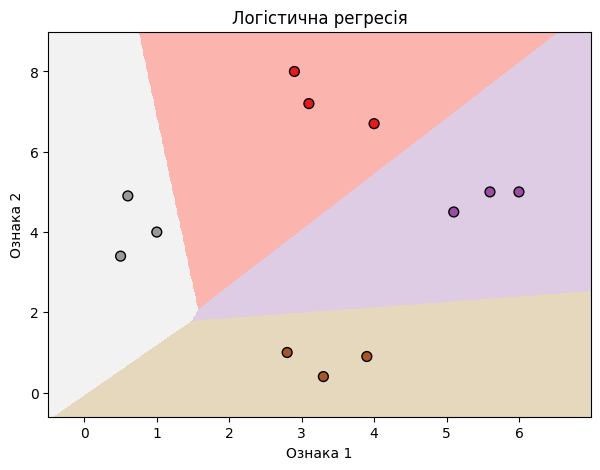

In [11]:
# Класифікація логістичною регресією (LR_1_task_3.py)
print("\n" + "="*50)
print("Логістична регресія")
print("="*50)

X_lr = np.array([
    [3.1, 7.2], [4.0, 6.7], [2.9, 8.0], [5.1, 4.5],
    [6.0, 5.0], [5.6, 5.0], [3.3, 0.4], [3.9, 0.9],
    [2.8, 1.0], [0.5, 3.4], [1.0, 4.0], [0.6, 4.9]
])
y_lr = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2, 3, 3, 3])

classifier_lr = linear_model.LogisticRegression(solver='liblinear', C=1)
classifier_lr.fit(X_lr, y_lr)

visualize_classifier(classifier_lr, X_lr, y_lr, title='Логістична регресія')

# Завдання 2.4: Gaussian Naive Bayes


Gaussian Naive Bayes
Точність Naive Bayes на тренувальній вибірці = 99.75 %


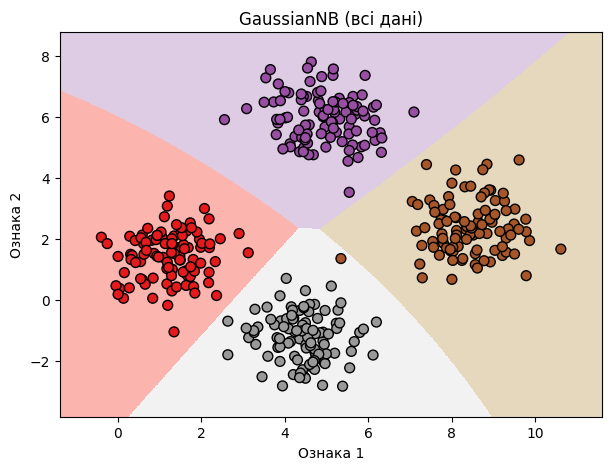

Точність GaussianNB на тестовому наборі (test_size=0.2) = 100.0 %


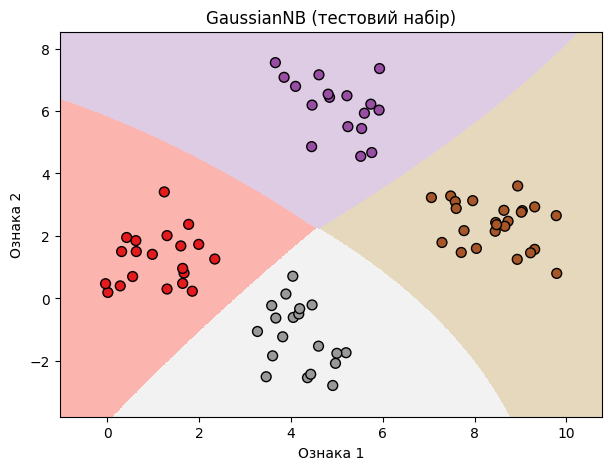

Accuracy (CV=3):  99.75%
Precision (CV=3): 99.76%
Recall (CV=3):    99.75%
F1-score (CV=3):  99.75%


In [12]:
# Наївний байєсівський класифікатор (LR_1_task_4.py)
print("\n" + "="*50)
print("Gaussian Naive Bayes")
print("="*50)

data = np.loadtxt('data_multivar_nb.txt', delimiter=',')
X_nb, y_nb = data[:, :-1], data[:, -1]

classifier_nb = GaussianNB()
classifier_nb.fit(X_nb, y_nb)
y_pred_nb = classifier_nb.predict(X_nb)

acc_all = 100.0 * (y_nb == y_pred_nb).sum() / X_nb.shape[0]
print("Точність Naive Bayes на тренувальній вибірці =", round(acc_all, 2), "%")
visualize_classifier(classifier_nb, X_nb, y_nb, title='GaussianNB (всі дані)')

X_train_nb, X_test_nb, y_train_nb, y_test_nb = train_test_split(
    X_nb, y_nb, test_size=0.2, random_state=3
)
classifier_nb_split = GaussianNB()
classifier_nb_split.fit(X_train_nb, y_train_nb)
y_test_pred_nb = classifier_nb_split.predict(X_test_nb)

acc_test = 100.0 * (y_test_nb == y_test_pred_nb).sum() / X_test_nb.shape[0]
print("Точність GaussianNB на тестовому наборі (test_size=0.2) =", round(acc_test, 2), "%")
visualize_classifier(classifier_nb_split, X_test_nb, y_test_nb, title='GaussianNB (тестовий набір)')

num_folds = 3
acc_cv = cross_val_score(classifier_nb, X_nb, y_nb, scoring='accuracy', cv=num_folds)
prec_cv = cross_val_score(classifier_nb, X_nb, y_nb, scoring='precision_weighted', cv=num_folds)
rec_cv = cross_val_score(classifier_nb, X_nb, y_nb, scoring='recall_weighted', cv=num_folds)
f1_cv = cross_val_score(classifier_nb, X_nb, y_nb, scoring='f1_weighted', cv=num_folds)

print(f"Accuracy (CV={num_folds}):  {round(100 * acc_cv.mean(), 2)}%")
print(f"Precision (CV={num_folds}): {round(100 * prec_cv.mean(), 2)}%")
print(f"Recall (CV={num_folds}):    {round(100 * rec_cv.mean(), 2)}%")
print(f"F1-score (CV={num_folds}):  {round(100 * f1_cv.mean(), 2)}%")

# Завдання 2.5: Метрики класифікації


Метрики класифікації та функції з прізвищем
Усі перевірки assert пройдено успішно!

--- Метрики для Random Forest (поріг = 0.5) ---
Accuracy:  0.671
Recall:    0.641
Precision: 0.681
F1-score:  0.660

--- Метрики для Random Forest (поріг = 0.25) ---
Accuracy:  0.578
Recall:    0.839
Precision: 0.551
F1-score:  0.665


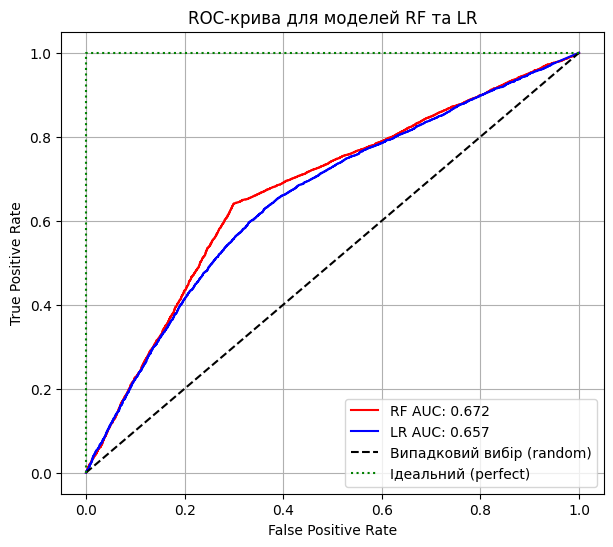

In [13]:
# Метрики якості класифікації (LR_1_task_5.py)
print("\n" + "="*50)
print("Метрики класифікації та функції з прізвищем")
print("="*50)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix, accuracy_score, recall_score,
    precision_score, f1_score, roc_curve, roc_auc_score
)

np.random.seed(42)
n_tn, n_fp, n_fn, n_tp = 5519, 2360, 2832, 5047

y_actual = np.concatenate([
    np.zeros(n_tn + n_fp, dtype=int),
    np.ones(n_fn + n_tp, dtype=int)
])

prob_rf = np.concatenate([
    np.random.uniform(0.05, 0.499, n_tn),  # TN
    np.random.uniform(0.500, 0.95, n_fp),  # FP
    np.random.uniform(0.05, 0.499, n_fn),  # FN
    np.random.uniform(0.500, 0.95, n_tp)   # TP
])

prob_lr = np.clip(prob_rf * 0.85 + np.random.normal(0, 0.1, len(y_actual)), 0.01, 0.99)

df = pd.DataFrame({
    'actual_label': y_actual,
    'model_RF': prob_rf,
    'model_LR': prob_lr
})

thresh = 0.5
df['predicted_RF'] = (df.model_RF >= thresh).astype('int')
df['predicted_LR'] = (df.model_LR >= thresh).astype('int')

def find_TP(y_true, y_pred):
    return sum((y_true == 1) & (y_pred == 1))

def find_FN(y_true, y_pred):
    return sum((y_true == 1) & (y_pred == 0))

def find_FP(y_true, y_pred):
    return sum((y_true == 0) & (y_pred == 1))

def find_TN(y_true, y_pred):
    return sum((y_true == 0) & (y_pred == 0))

def find_conf_matrix_values(y_true, y_pred):
    TP = find_TP(y_true, y_pred)
    FN = find_FN(y_true, y_pred)
    FP = find_FP(y_true, y_pred)
    TN = find_TN(y_true, y_pred)
    return TP, FN, FP, TN

def demchyshyn_confusion_matrix(y_true, y_pred):
    TP, FN, FP, TN = find_conf_matrix_values(y_true, y_pred)
    return np.array([[TN, FP], [FN, TP]])

def demchyshyn_accuracy_score(y_true, y_pred):
    TP, FN, FP, TN = find_conf_matrix_values(y_true, y_pred)
    return (TP + TN) / (TP + TN + FP + FN)

def demchyshyn_recall_score(y_true, y_pred):
    TP, FN, FP, TN = find_conf_matrix_values(y_true, y_pred)
    return TP / (TP + FN)

def demchyshyn_precision_score(y_true, y_pred):
    TP, FN, FP, TN = find_conf_matrix_values(y_true, y_pred)
    return TP / (TP + FP)

def demchyshyn_f1_score(y_true, y_pred):
    recall = demchyshyn_recall_score(y_true, y_pred)
    precision = demchyshyn_precision_score(y_true, y_pred)
    return 2 * (precision * recall) / (precision + recall)

assert np.array_equal(demchyshyn_confusion_matrix(df.actual_label.values, df.predicted_RF.values),
                      confusion_matrix(df.actual_label.values, df.predicted_RF.values)), 'Помилка в demchyshyn_confusion_matrix (RF)'
assert np.array_equal(demchyshyn_confusion_matrix(df.actual_label.values, df.predicted_LR.values),
                      confusion_matrix(df.actual_label.values, df.predicted_LR.values)), 'Помилка в demchyshyn_confusion_matrix (LR)'

assert round(demchyshyn_accuracy_score(df.actual_label.values, df.predicted_RF.values), 6) == \
       round(accuracy_score(df.actual_label.values, df.predicted_RF.values), 6), 'Помилка accuracy RF'
assert round(demchyshyn_recall_score(df.actual_label.values, df.predicted_RF.values), 6) == \
       round(recall_score(df.actual_label.values, df.predicted_RF.values), 6), 'Помилка recall RF'
assert round(demchyshyn_precision_score(df.actual_label.values, df.predicted_RF.values), 6) == \
       round(precision_score(df.actual_label.values, df.predicted_RF.values), 6), 'Помилка precision RF'
assert round(demchyshyn_f1_score(df.actual_label.values, df.predicted_RF.values), 6) == \
       round(f1_score(df.actual_label.values, df.predicted_RF.values), 6), 'Помилка F1 RF'

print("Усі перевірки assert пройдено успішно!")

for th in [0.5, 0.25]:
    pred_rf_th = (df.model_RF >= th).astype('int').values
    print(f"\n--- Метрики для Random Forest (поріг = {th}) ---")
    print(f"Accuracy:  {demchyshyn_accuracy_score(df.actual_label.values, pred_rf_th):.3f}")
    print(f"Recall:    {demchyshyn_recall_score(df.actual_label.values, pred_rf_th):.3f}")
    print(f"Precision: {demchyshyn_precision_score(df.actual_label.values, pred_rf_th):.3f}")
    print(f"F1-score:  {demchyshyn_f1_score(df.actual_label.values, pred_rf_th):.3f}")

fpr_RF, tpr_RF, _ = roc_curve(df.actual_label.values, df.model_RF.values)
fpr_LR, tpr_LR, _ = roc_curve(df.actual_label.values, df.model_LR.values)
auc_RF = roc_auc_score(df.actual_label.values, df.model_RF.values)
auc_LR = roc_auc_score(df.actual_label.values, df.model_LR.values)

plt.figure(figsize=(7, 6))
plt.plot(fpr_RF, tpr_RF, 'r-', label=f'RF AUC: {auc_RF:.3f}')
plt.plot(fpr_LR, tpr_LR, 'b-', label=f'LR AUC: {auc_LR:.3f}')
plt.plot([0, 1], [0, 1], 'k--', label='Випадковий вибір (random)')
plt.plot([0, 0, 1, 1], [0, 1, 1, 1], 'g:', label='Ідеальний (perfect)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-крива для моделей RF та LR')
plt.legend()
plt.grid(True)
plt.show()

# Завдання 2.6: Support Vector Machine (SVM)


Support Vector Machine (SVM) vs Naive Bayes
Результати 3-кратної крос-валідації для SVM:
Accuracy:  99.75%
Precision: 99.76%
Recall:    99.75%
F1-score:  99.75%


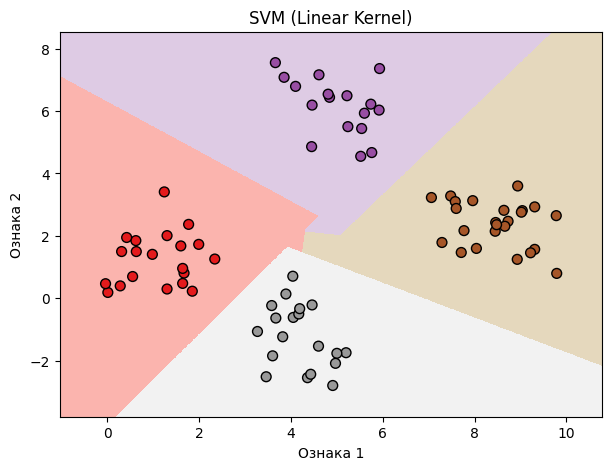


Порівняльна таблиця моделей:
  Метрика Naive Bayes (GNB) SVM (Linear)
 Accuracy            99.75%       99.75%
Precision            99.76%       99.76%
   Recall            99.75%       99.75%
 F1-score            99.75%       99.75%


In [14]:
# Класифікація через Support Vector Machine (LR_1_task_6.py)
print("\n" + "="*50)
print("Support Vector Machine (SVM) vs Naive Bayes")
print("="*50)

svm_classifier = SVC(kernel='linear', C=1.0, random_state=3)
svm_classifier.fit(X_train_nb, y_train_nb)
y_svm_pred = svm_classifier.predict(X_test_nb)

acc_svm_cv = cross_val_score(svm_classifier, X_nb, y_nb, scoring='accuracy', cv=num_folds)
prec_svm_cv = cross_val_score(svm_classifier, X_nb, y_nb, scoring='precision_weighted', cv=num_folds)
rec_svm_cv = cross_val_score(svm_classifier, X_nb, y_nb, scoring='recall_weighted', cv=num_folds)
f1_svm_cv = cross_val_score(svm_classifier, X_nb, y_nb, scoring='f1_weighted', cv=num_folds)

print("Результати 3-кратної крос-валідації для SVM:")
print(f"Accuracy:  {round(100 * acc_svm_cv.mean(), 2)}%")
print(f"Precision: {round(100 * prec_svm_cv.mean(), 2)}%")
print(f"Recall:    {round(100 * rec_svm_cv.mean(), 2)}%")
print(f"F1-score:  {round(100 * f1_svm_cv.mean(), 2)}%")

visualize_classifier(svm_classifier, X_test_nb, y_test_nb, title='SVM (Linear Kernel)')

comparison_df = pd.DataFrame({
    'Метрика': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Naive Bayes (GNB)': [
        f"{100*acc_cv.mean():.2f}%",
        f"{100*prec_cv.mean():.2f}%",
        f"{100*rec_cv.mean():.2f}%",
        f"{100*f1_cv.mean():.2f}%"
    ],
    'SVM (Linear)': [
        f"{100*acc_svm_cv.mean():.2f}%",
        f"{100*prec_svm_cv.mean():.2f}%",
        f"{100*rec_svm_cv.mean():.2f}%",
        f"{100*f1_svm_cv.mean():.2f}%"
    ]
})
print("\nПорівняльна таблиця моделей:")
print(comparison_df.to_string(index=False))